# Session 6 lecture: Visualisation principles

<p class="lead">
A chart is an argument made with shapes and colours. This lecture shows how the eye reads a chart, which choices make a comparison easy or hard, and how to turn a default plot into one a manager understands in seconds.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/06_visualisation_principles_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Start by answering the Session 5 quiz. Write your answers down before the discussion.

---

## What you will be able to explain

1. How to choose a chart from the **task** the reader has to do.
2. Why some encodings (position, length) are read more accurately than others (angle, area, colour).
3. Which **pre-attentive attributes** make one thing stand out, and how to use only one at a time.
4. How to remove **non-data ink** without removing meaning.
5. How the **Gestalt principles** decide what the reader compares.
6. When to use **categorical**, **sequential** and **diverging** colour, and how to stay colour-blind safe.
7. When an axis must start at zero, and why **dual axes** are dangerous.
8. How to write a **message title**, add **annotations** and use **small multiples**.

| Part | Topic |
|---|---|
| 1 | Choose the chart from the task |
| 2 | How accurately we read encodings |
| 3 | Pre-attentive attributes |
| 4 | Data-ink and decluttering |
| 5 | Gestalt: what belongs together |
| 6 | Colour with a job |
| 7 | Honest axes |
| 8 | Message titles and annotation |
| 9 | Small multiples |

This lecture goes deeper than the Foundations pages [Designing clear visuals](../foundations/visual-design.md) and [How statistics can mislead](../foundations/misleading-statistics.md). Read them first if you have not.

> **How to use this notebook**
>
> Every idea comes as a **before** and an **after** chart, both drawn by code. When you see **Predict, then reveal**, write your answer first and only then run the next cell.

Run the setup cell first. It prepares pandas, the course chart style and the retail table.

In [1]:
# Course data setup. Run this cell first; you do not need to understand it yet.
# It downloads the Superstore sample from Tableau's website, checks it is the
# exact version this course was written for, and prepares the order-lines table.
import hashlib
import os
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

SOURCE_URL = "https://public.tableau.com/app/sample-data/sample_-_superstore.xls"
EXPECTED_SHA256 = "5045ed4fec49cae2cc0dfc5ab0d204ba09efa767fe00c996822499e8cc42fbbd"
SOURCE_FILE = os.environ.get("COURSE_XLS_PATH", "sample_-_superstore.xls")

try:
    import xlrd  # noqa: F401  (needed to read .xls files)
except ImportError:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "xlrd"])

if not os.path.exists(SOURCE_FILE):
    urllib.request.urlretrieve(SOURCE_URL, SOURCE_FILE)

with open(SOURCE_FILE, "rb") as f:
    digest = hashlib.sha256(f.read()).hexdigest()
if digest != EXPECTED_SHA256:
    print("WARNING: Tableau has changed this sample file since the course was written.")
    print("Your numbers will differ from the lesson. Ask your facilitator for the course copy.")


def load_orders():
    """Return one row per order line, orders placed 2023-01-01 to 2025-12-31."""
    raw = pd.read_excel(SOURCE_FILE, sheet_name="Orders")
    returns = pd.read_excel(SOURCE_FILE, sheet_name="Returns")

    # Orders with more than one Customer ID (a known data issue), found before filtering.
    ids_per_order = raw.groupby("Order ID")["Customer ID"].nunique()
    conflict_orders = set(ids_per_order[ids_per_order > 1].index)

    in_scope = (raw["Order Date"] >= "2023-01-01") & (raw["Order Date"] < "2026-01-01")
    df = raw.loc[in_scope].copy()

    df = df.rename(columns={
        "Row ID": "row_id", "Order ID": "order_id", "Order Date": "order_date",
        "Ship Date": "ship_date", "Ship Mode": "ship_mode", "Customer ID": "customer_id",
        "Segment": "segment", "Country/Region": "country_region", "Region": "region",
        "Category": "category", "Sub-Category": "sub_category", "Product ID": "product_id",
        "Product Name": "product_name", "Sales": "sales", "Quantity": "quantity",
        "Discount": "discount", "Profit": "profit",
    })
    df["returned_order_flag"] = df["order_id"].isin(set(returns["Order ID"])).astype(int)
    df["customer_order_conflict"] = df["order_id"].isin(conflict_orders).astype(int)
    df["customer_analysis_eligible"] = 1 - df["customer_order_conflict"]
    df["order_to_ship_days"] = (df["ship_date"] - df["order_date"]).dt.days
    df["order_month"] = df["order_date"].dt.to_period("M").dt.to_timestamp()

    columns = [
        "row_id", "order_id", "order_date", "ship_date", "ship_mode", "customer_id",
        "segment", "country_region", "region", "category", "sub_category", "product_id",
        "product_name", "sales", "quantity", "discount", "profit", "returned_order_flag",
        "customer_analysis_eligible", "customer_order_conflict", "order_to_ship_days",
        "order_month",
    ]
    return df[columns].sort_values("row_id").reset_index(drop=True)


pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Setup complete.")

Setup complete.


The next cell loads the table and defines a few colours used throughout. `GREY` is for context, one strong colour is for the thing that matters. `OKABE_ITO` is a palette designed to stay distinguishable for people with the common forms of colour blindness. The small `commas` helper writes axis numbers with thousands separators.

In [2]:
import numpy as np
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

df = load_orders()

BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"
INK = "#55534e"
OKABE_ITO = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
rng = np.random.default_rng(6)  # fixed seed: the made-up examples look the same every run


def commas(ax, axis="y"):
    # Write large axis numbers with thousands separators: 250,000 instead of 250000.
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_formatter("{x:,.0f}")


print("Order lines loaded:", len(df))

Order lines loaded: 6815


---

## Part 1: Choose the chart from the task

Do not start from "which chart looks good". Start from **what the reader must do** with the numbers.

| Task | The reader asks | Good first choice | Usually avoid |
|---|---|---|---|
| **Compare** categories | Which is bigger, and by how much? | Sorted bar chart (horizontal when labels are long) | Pie, 3D bars |
| **Composition** | What share does each part make? | Stacked bar, or a bar of shares; a pie only for two or three parts | Pie with many slices |
| **Distribution** | What values are typical, how spread, any outliers? | Histogram, box plot, strip plot | Bar of the average alone |
| **Relationship** | Do two measures move together? | Scatter plot | Two lines on dual axes |
| **Change over time** | Rising, falling, seasonal? | Line chart (time on the x-axis) | Unsorted bars, pie per year |

### Predict, then reveal

The next chart shows Sales for each of the 17 product sub-categories. Before you run it, get a pen ready. From the chart alone, write down:

1. Which sub-category is **fifth** largest?
2. Roughly how many times bigger is the largest slice than the **third** largest?

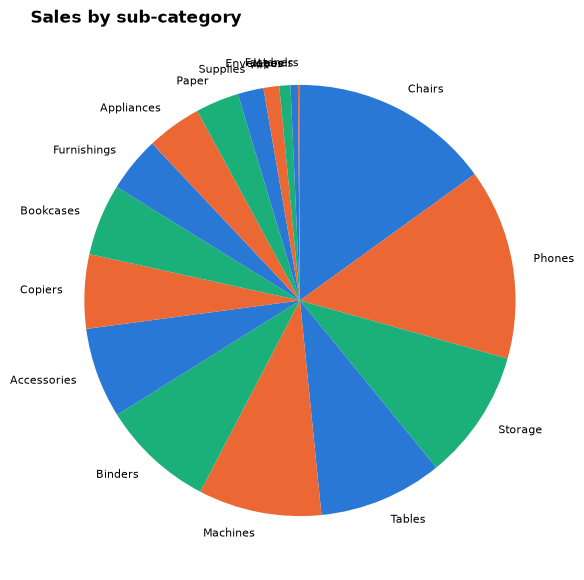

In [3]:
by_sub = df.groupby("sub_category")["sales"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(by_sub, labels=by_sub.index, startangle=90, counterclock=False,
       textprops={"fontsize": 8})
ax.set_title("Sales by sub-category")
plt.show()

Now the same numbers as a sorted bar chart. Check your two answers.

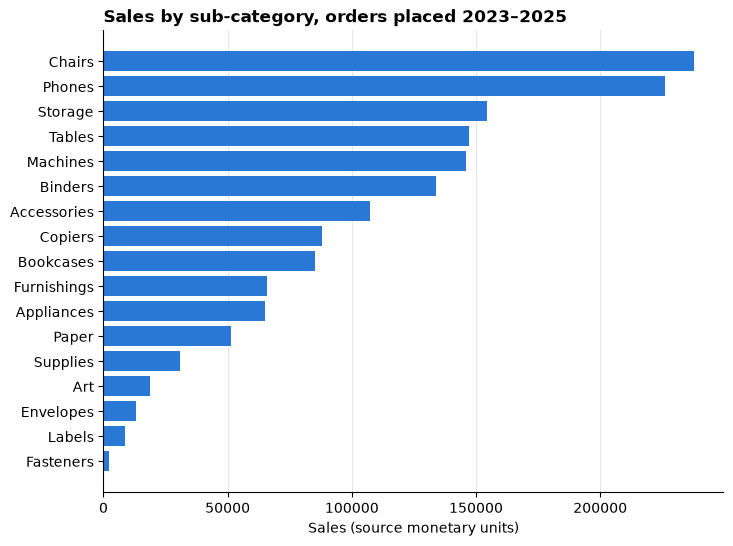

Fifth largest: Machines
Largest divided by third largest: 1.54


In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(by_sub.index[::-1], by_sub.values[::-1], color=BLUE)
ax.grid(axis="y", visible=False)
ax.set_title("Sales by sub-category, orders placed 2023–2025")
ax.set_xlabel("Sales (source monetary units)")
plt.show()

top = by_sub.iloc[0]
print("Fifth largest:", by_sub.index[4])
print("Largest divided by third largest:", round(top / by_sub.iloc[2], 2))

With the bars, the ranking is the order on the page and the size ratio is a comparison of lengths from a common baseline. With the pie, you had to compare angles of slices that do not share a starting line.

> **Check your understanding 1**
>
> For each request, name the task and a first chart choice:
>
> 1. "How long do our deliveries usually take, and how often are they very late?"
> 2. "Has the share of online sales grown over the last three years?"
> 3. "Do customers who get bigger discounts buy more items?"
> 4. "Which of our 12 warehouses had the highest return rate last quarter?"

---

## Part 2: How accurately we read encodings

An **encoding** is how a number becomes something visible: a position, a length, an angle, an area, a colour. Experiments by William Cleveland and Robert McGill (1984), repeated many times since, found that people judge some encodings much more accurately than others.

| Rank | Encoding | Example |
|---|---|---|
| 1 (most accurate) | **Position on a common scale** | Dots or bar ends against one axis |
| 2 | **Length** | Bars that start at the same baseline |
| 3 | **Angle and slope** | Pie slices, line steepness |
| 4 | **Area** | Bubbles, treemaps |
| 5 (least accurate) | **Colour intensity and hue** | Shaded maps, heatmaps |

So: put the most important comparison on **position or length**. Use colour and area for secondary information, or for highlighting.

### Predict, then reveal

Five made-up values are shown as pie slices and as bubbles. Rank them from largest to smallest using only these two pictures, and write your ranking down.

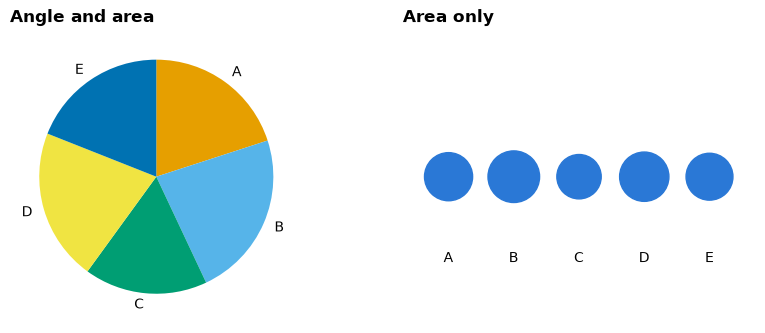

In [5]:
values = pd.Series({"A": 20, "B": 23, "C": 17, "D": 21, "E": 19})

fig, (ax_pie, ax_bubble) = plt.subplots(1, 2, figsize=(10, 3.8))
ax_pie.pie(values, labels=values.index, startangle=90, counterclock=False, colors=OKABE_ITO[:5])
ax_pie.set_title("Angle and area")

ax_bubble.scatter(range(len(values)), [0] * len(values), s=values * 60, color=BLUE)
for i, label in enumerate(values.index):
    ax_bubble.text(i, -0.35, label, ha="center")
ax_bubble.set_xlim(-0.7, 4.7)
ax_bubble.set_ylim(-0.6, 0.6)
ax_bubble.axis("off")
ax_bubble.set_title("Area only")
plt.show()

Now the same five values as bars on a common baseline.

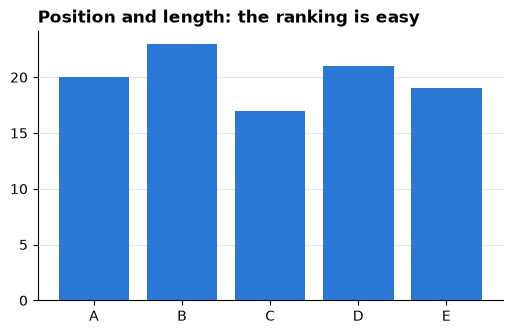

True ranking: B, D, A, E, C


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(values.index, values, color=BLUE)
ax.grid(axis="x", visible=False)
ax.set_title("Position and length: the ranking is easy")
plt.show()

print("True ranking:", ", ".join(values.sort_values(ascending=False).index))

Most people get the bubbles and slices partly wrong when the values are close, and nearly everyone gets the bars right. This is the main reason analysts prefer bars and dots.

> **Check your understanding 2**
>
> A colleague shows a map where each region's profit is shown only by its shade of green. Name one question about the regions this map answers badly, and suggest a chart that answers it better.

---

## Part 3: Pre-attentive attributes

Some differences are seen in a fraction of a second, before you consciously search: **colour**, **size**, **position**, **orientation**, **shape**, **enclosure**. They are called **pre-attentive** attributes.

### Predict, then reveal

The next cell draws two panels. In each, find the odd one out. Which panel is faster, and why?

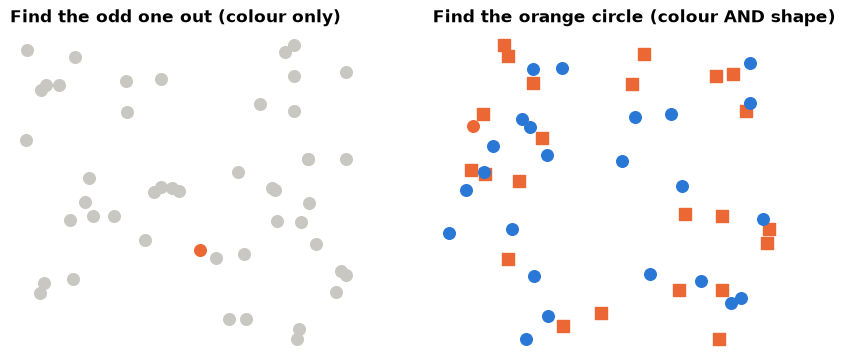

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))

xy = rng.uniform(0, 1, size=(48, 2))
ax1.scatter(xy[1:, 0], xy[1:, 1], s=70, color=GREY)
ax1.scatter(xy[0, 0], xy[0, 1], s=70, color=ORANGE)
ax1.set_title("Find the odd one out (colour only)")

xy2 = rng.uniform(0, 1, size=(48, 2))
half = len(xy2) // 2
ax2.scatter(xy2[1:half, 0], xy2[1:half, 1], s=70, color=ORANGE, marker="s")
ax2.scatter(xy2[half:, 0], xy2[half:, 1], s=70, color=BLUE, marker="o")
ax2.scatter(xy2[0, 0], xy2[0, 1], s=70, color=ORANGE, marker="o")
ax2.set_title("Find the orange circle (colour AND shape)")

for ax in (ax1, ax2):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

In the left panel the orange dot "pops out" at once. In the right panel you must scan, because the target differs only by a **combination** of colour and shape, and combinations are not pre-attentive.

**Lesson for charts:**

1. Use **one** pre-attentive attribute to mark what matters, usually a single strong colour against grey.
2. If everything is highlighted, nothing is. Five bright colours give the eye five places to look.
3. Do not ask the reader to decode combinations ("orange squares are 2024 West").

---

## Part 4: Data-ink and decluttering

Edward Tufte's **data-ink ratio** asks: how much of the ink shows data? Everything else (heavy grids, borders, colours with no meaning, rotated labels) costs the reader attention.

Here is matplotlib's **default** style with Profit by sub-category. The `plt.style.context("default")` line switches off the course style for this one chart.

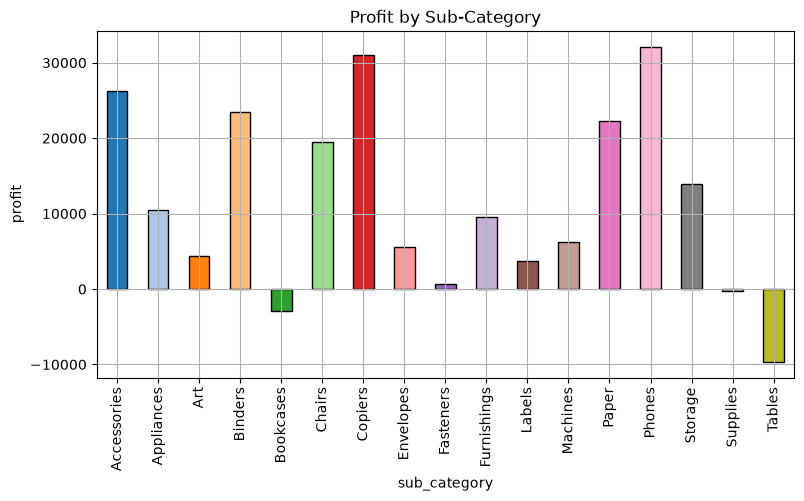

In [8]:
profit_sub = df.groupby("sub_category")["profit"].sum()

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    profit_sub.plot(kind="bar", ax=ax, color=plt.cm.tab20.colors, edgecolor="black")
    ax.grid(True)
    ax.set_title("Profit by Sub-Category")
    ax.set_ylabel("profit")
    plt.show()

### Predict, then reveal

List three things on this chart that do **not** help the reader, and one question it makes hard to answer. Then run the next cell.

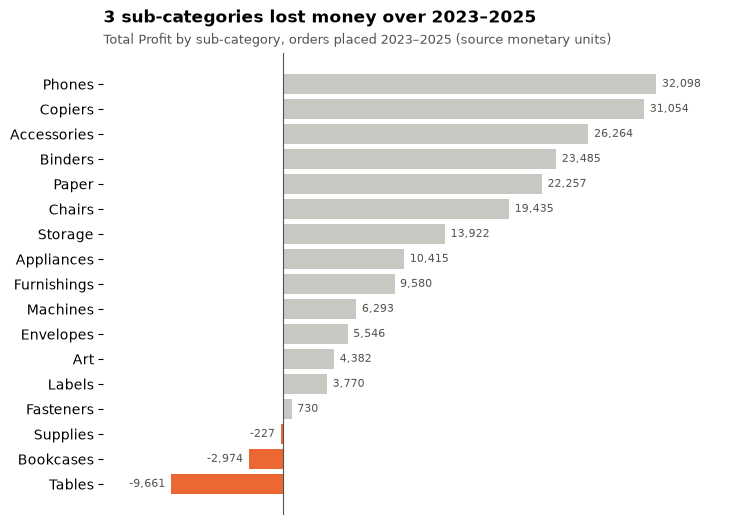

In [9]:
profit_sorted = profit_sub.sort_values()
colours = [ORANGE if value < 0 else GREY for value in profit_sorted]
offset = 0.015 * profit_sorted.abs().max()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(profit_sorted.index, profit_sorted, color=colours)
ax.axvline(0, color=INK, linewidth=0.8)
for name, value in profit_sorted.items():
    ax.text(value + offset if value >= 0 else value - offset, name, f"{value:,.0f}",
            va="center", ha="left" if value >= 0 else "right", fontsize=8, color=INK)

ax.set_xlim(profit_sorted.min() * 1.6, profit_sorted.max() * 1.18)
ax.set_xticks([])
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)

losers = (profit_sorted < 0).sum()
ax.set_title(f"{losers} sub-categories lost money over 2023–2025", pad=22)
ax.text(0, 1.02, "Total Profit by sub-category, orders placed 2023–2025 (source monetary units)",
        transform=ax.transAxes, fontsize=9, color=INK)
plt.show()

What changed, and why:

| Change | Principle |
|---|---|
| Sorted by value | The ranking is now the reading order |
| Horizontal bars | Long labels are readable without tilting your head |
| One colour with meaning (orange = loss), grey for the rest | One pre-attentive attribute, one message |
| Values written on the bars, value axis removed | Exact numbers without a grid to trace |
| A zero line kept | It separates profit from loss, so it carries data |
| Title states the finding; subtitle states scope and units | The reader knows what to look for and what was counted |

> **Do not overdo it**
>
> Decluttering stops when removing something would lose meaning: units, the period, the scope or a zero line. Clarity, not minimalism.

> **Check your understanding 3**
>
> The "after" chart removed the value axis. Give one situation where you should **keep** a value axis instead of writing numbers on the bars.

---

## Part 5: Gestalt: what belongs together

Gestalt principles describe how we group what we see. You can use them to decide what the reader compares.

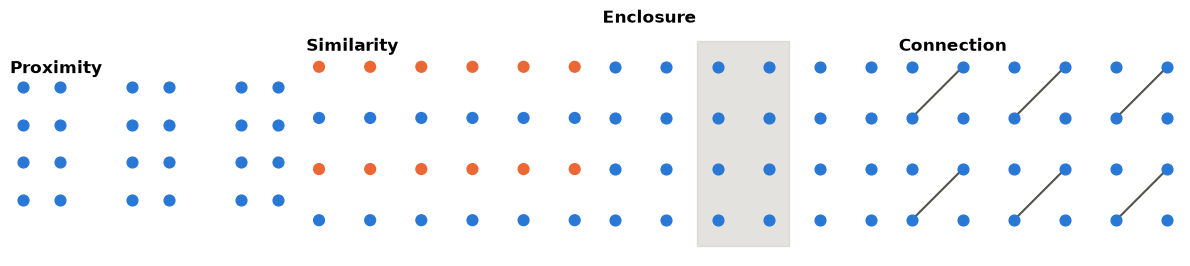

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
gx, gy = np.meshgrid(np.arange(6), np.arange(4))
gx, gy = gx.ravel(), gy.ravel()

# Proximity: same dots, but columns pushed into pairs
axes[0].scatter(gx + (gx // 2) * 0.9, gy, s=60, color=BLUE)
axes[0].set_title("Proximity")

# Similarity: equal spacing, rows coloured alternately
axes[1].scatter(gx, gy, s=60, color=[ORANGE if row % 2 else BLUE for row in gy])
axes[1].set_title("Similarity")

# Enclosure: equal spacing and colour, one box
axes[2].scatter(gx, gy, s=60, color=BLUE)
axes[2].add_patch(Rectangle((1.6, -0.5), 1.8, 4, color=GREY, alpha=0.5, zorder=0))
axes[2].set_title("Enclosure")

# Connection: equal spacing, some dots joined
axes[3].scatter(gx, gy, s=60, color=BLUE)
for x0 in (0, 2, 4):
    for y0 in (0, 2):
        axes[3].plot([x0, x0 + 1], [y0, y0 + 1], color=INK, linewidth=1.5, zorder=0)
axes[3].set_title("Connection")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_aspect("equal")
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
plt.show()

| Principle | What you saw | Use in charts |
|---|---|---|
| **Proximity** | Pairs of columns | Bars placed close together are compared first |
| **Similarity** | Rows, even though spacing is equal | Same colour = same category across panels |
| **Enclosure** | The boxed columns form a group | Shade a period (a promotion, a recession) |
| **Connection** | Joined dots read as pairs | Lines join points that belong to one series |

### Proximity decides the comparison

The same Sales numbers, grouped two ways. Which question does each chart answer easily?

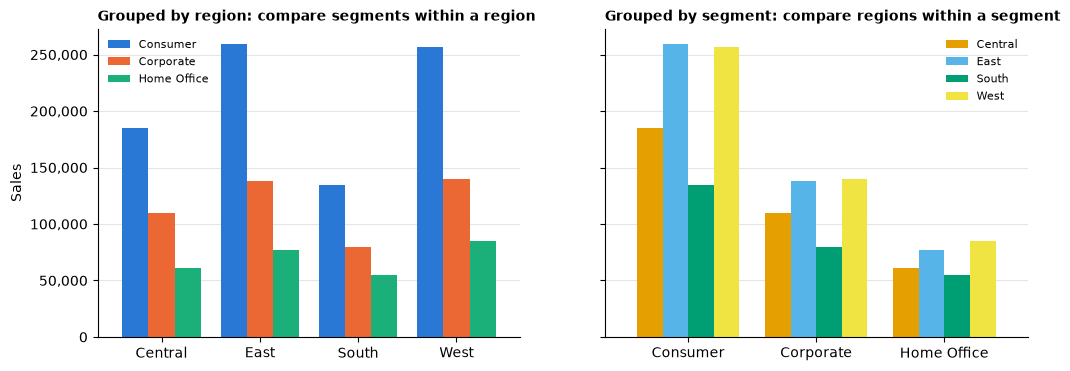

In [11]:
pivot = df.groupby(["region", "segment"])["sales"].sum().unstack()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
pivot.plot(kind="bar", ax=ax1, rot=0, color=[BLUE, ORANGE, GREEN], width=0.8)
ax1.set_title("Grouped by region: compare segments within a region", fontsize=10)
pivot.T.plot(kind="bar", ax=ax2, rot=0, color=OKABE_ITO[:4], width=0.8)
ax2.set_title("Grouped by segment: compare regions within a segment", fontsize=10)
for ax in (ax1, ax2):
    ax.set_xlabel("")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, fontsize=8)
ax1.set_ylabel("Sales")
commas(ax1)
plt.show()

Bars that sit next to each other get compared. Put **next to each other** the things your question compares.

---

## Part 6: Colour with a job

Colour should do one of three jobs. Match the palette to the job.

| Data | Palette type | Example | Rule |
|---|---|---|---|
| **Categories** with no order | Categorical: distinct hues | Segments, regions | At most about six; same category, same colour everywhere |
| **Ordered amounts** from low to high | Sequential: one hue, light to dark | Sales by region and year | Darker = more |
| **Values around a meaningful middle** | Diverging: two hues, neutral centre | Profit ratio around 0% | The neutral colour must sit exactly at the middle value |

### Sequential: amounts

The helper below draws a table as a heatmap and writes each value in its cell, in white on dark cells and black on light cells.

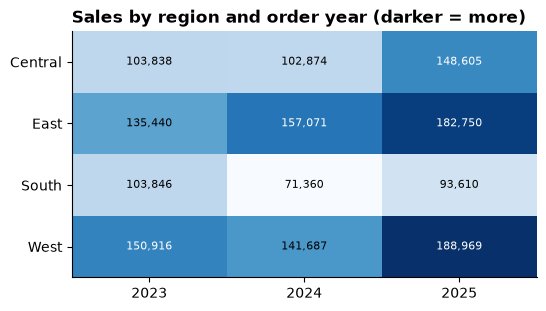

In [12]:
def heatmap(ax, table, cmap, norm=None, fmt="{:,.0f}"):
    image = ax.imshow(table.values, cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns)
    ax.set_yticks(range(table.shape[0]), table.index)
    ax.grid(False)
    for (i, j), value in np.ndenumerate(table.values):
        r, g, b, _ = image.cmap(image.norm(value))
        text_colour = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black"
        ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=8, color=text_colour)
    return image


sales_year = df.assign(year=df["order_date"].dt.year).pivot_table(
    index="region", columns="year", values="sales", aggfunc="sum")

fig, ax = plt.subplots(figsize=(6, 3.2))
heatmap(ax, sales_year, cmap="Blues")
ax.set_title("Sales by region and order year (darker = more)")
plt.show()

### Predict, then reveal: diverging

Profit ratio (Profit ÷ Sales) for each sub-category and region. Zero is special: above it the business makes money, below it loses money. First, a sequential palette. Can you tell at a glance which cells are **losses**?

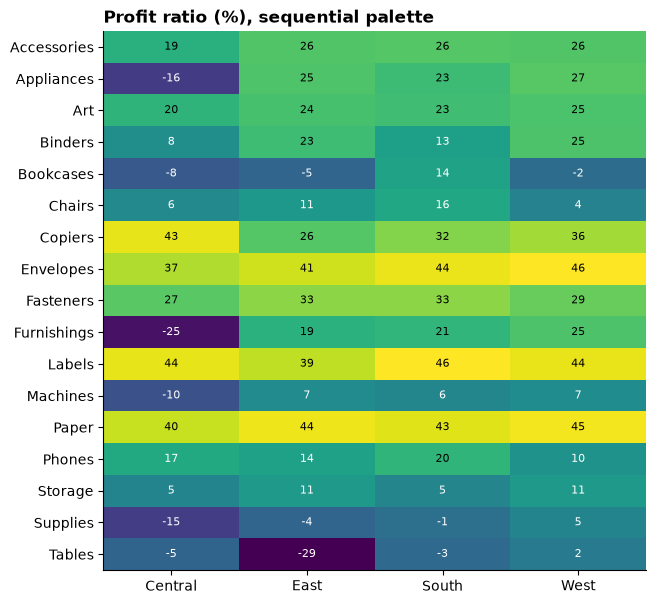

In [13]:
totals = df.groupby(["sub_category", "region"])[["profit", "sales"]].sum()
profit_ratio = (totals["profit"] / totals["sales"] * 100).unstack()

fig, ax = plt.subplots(figsize=(7, 7))
heatmap(ax, profit_ratio, cmap="viridis", fmt="{:.0f}")
ax.set_title("Profit ratio (%), sequential palette")
plt.show()

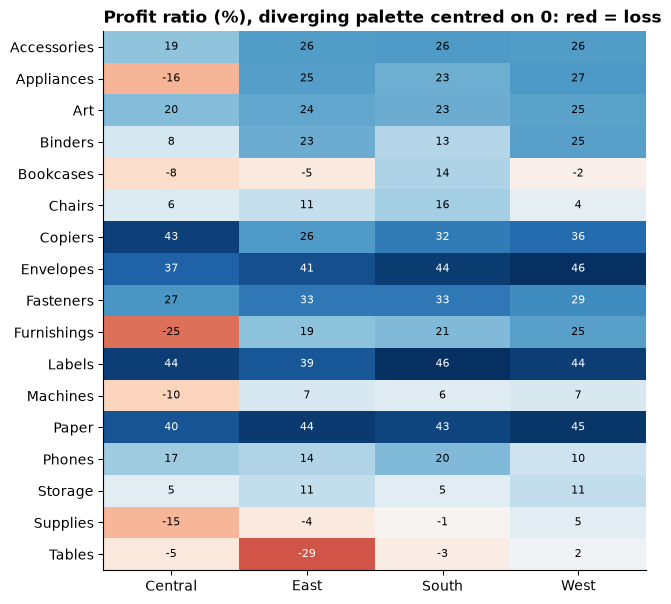

In [14]:
limit = profit_ratio.abs().max().max()
centred = TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit)

fig, ax = plt.subplots(figsize=(7, 7))
heatmap(ax, profit_ratio, cmap="RdBu", norm=centred, fmt="{:.0f}")
ax.set_title("Profit ratio (%), diverging palette centred on 0: red = loss")
plt.show()

With the diverging palette, every loss is red and every profit blue, and the palest cells are close to break-even. The sequential palette hid the most important boundary in the data.

> **Colour-blind safety**
>
> About 1 in 12 men and 1 in 200 women have some colour-vision deficiency, most often red–green. Safe habits:
>
> 1. Avoid red-versus-green as the only difference. Red–blue (as above) or orange–blue are safer.
> 2. Use a tested palette such as Okabe–Ito (`OKABE_ITO` above) for categories.
> 3. Do not rely on colour alone: add labels, positions or patterns.

### Highlight one series, grey the rest

Seventeen sub-categories over time with default colours: the default cycle has only ten colours, so some lines share a colour.

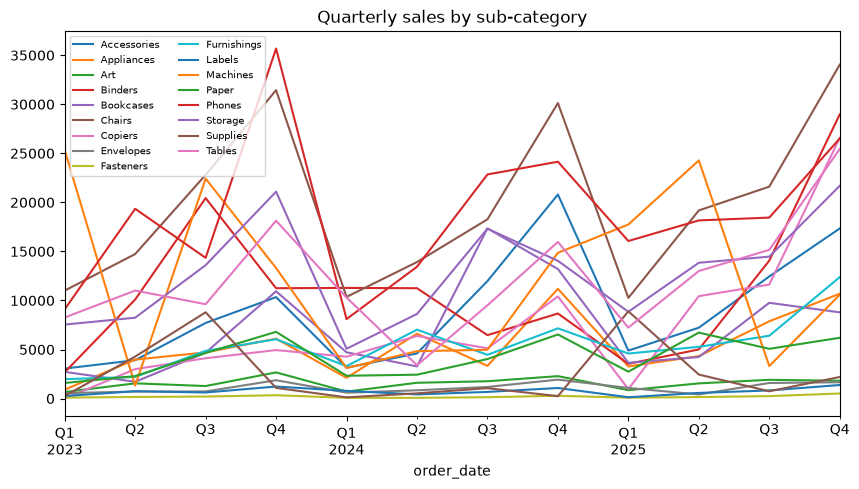

In [15]:
quarter = df["order_date"].dt.to_period("Q").dt.to_timestamp()
by_quarter = df.groupby([quarter, "sub_category"])["sales"].sum().unstack().fillna(0)  # no lines = no Sales

with plt.style.context("default"):
    ax = by_quarter.plot(figsize=(10, 5), title="Quarterly sales by sub-category")
    ax.legend(fontsize=7, ncol=2, loc="upper left")
    plt.show()

Now decide what the chart is **about**. Here: the sub-category whose yearly Sales grew most, in source monetary units, between the first and last year. The code finds it; the chart puts it in colour and everything else in grey context.

/var/folders/qr/z61dfxk90914kcsdy7jskgqr0000gn/T/ipykernel_52694/3374556044.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.set_xlim(right=by_quarter.index[-1] + pd.Timedelta(days=200))


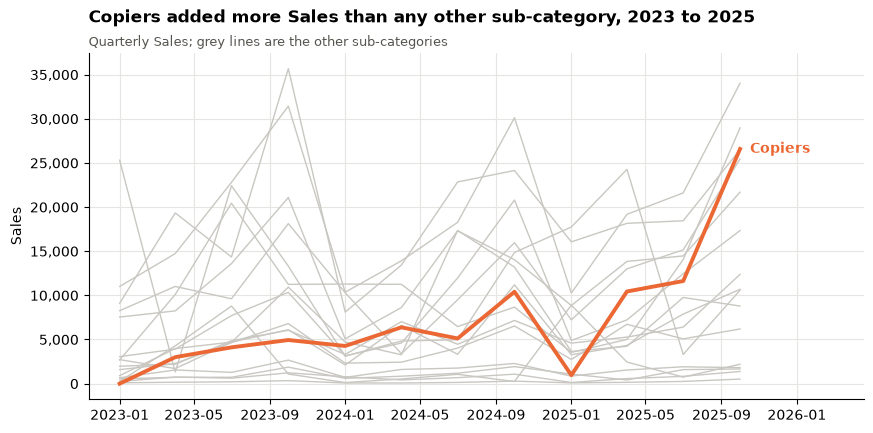

Copiers yearly Sales, 2023: 12,050 | 2025: 49,599


In [16]:
yearly = df.groupby([df["order_date"].dt.year, "sub_category"])["sales"].sum().unstack()
growth = (yearly.iloc[-1] - yearly.iloc[0]).sort_values()
focus = growth.index[-1]

fig, ax = plt.subplots(figsize=(10, 4.5))
for name in by_quarter.columns:
    if name != focus:
        ax.plot(by_quarter.index, by_quarter[name], color=GREY, linewidth=1)
ax.plot(by_quarter.index, by_quarter[focus], color=ORANGE, linewidth=2.8)
ax.text(by_quarter.index[-1], by_quarter[focus].iloc[-1], f"  {focus}", color=ORANGE,
        va="center", fontweight="bold")
ax.set_xlim(right=by_quarter.index[-1] + pd.Timedelta(days=200))
ax.set_title(f"{focus} added more Sales than any other sub-category, {yearly.index[0]} to {yearly.index[-1]}", pad=22)
ax.text(0, 1.02, "Quarterly Sales; grey lines are the other sub-categories",
        transform=ax.transAxes, fontsize=9, color=INK)
ax.set_ylabel("Sales")
commas(ax)
plt.show()

print(f"{focus} yearly Sales, {yearly.index[0]}: {yearly[focus].iloc[0]:,.0f} | {yearly.index[-1]}: {yearly[focus].iloc[-1]:,.0f}")

> **Check your understanding 4**
>
> Which palette type (categorical, sequential or diverging) fits each case, and why?
>
> 1. Customer satisfaction score from 1 to 10 for each store.
> 2. Change in headcount versus last year, by department (some up, some down).
> 3. Five product lines on one line chart.

---

## Part 7: Honest axes

### Bars must start at zero

A bar's **length** is the encoding. If the axis does not start at zero, the lengths lie. Average order value (AOV = Sales ÷ distinct orders) by region:

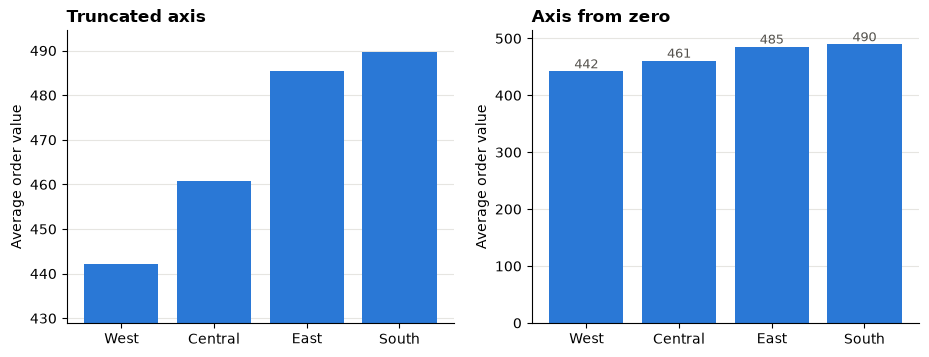

Largest AOV divided by smallest: 1.11


In [17]:
region_totals = df.groupby("region").agg(sales=("sales", "sum"), orders=("order_id", "nunique"))
aov = (region_totals["sales"] / region_totals["orders"]).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.bar(aov.index, aov, color=BLUE)
ax1.set_ylim(aov.min() * 0.97, aov.max() * 1.01)
ax1.set_title("Truncated axis")
ax2.bar(aov.index, aov, color=BLUE)
for i, value in enumerate(aov):
    ax2.text(i, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=9, color=INK)
ax2.set_title("Axis from zero")
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("Average order value")
plt.show()

print("Largest AOV divided by smallest:", round(aov.max() / aov.min(), 2))

On the left, the tallest bar looks several times taller than the shortest. The printed ratio shows the true difference.

**Lines are different.** A line's message is its **shape** (rising, falling, seasonal), read from position, not length. A line chart may zoom in to the range of the data, as long as the axis is labelled. The rule is: **bars from zero; lines may zoom, with labels**.

### Dual axes: two scales, any story you like

A dual-axis chart puts two measures on one picture, each with its own scale. The person drawing it chooses both scales, and with them the "story". Two made-up monthly series:

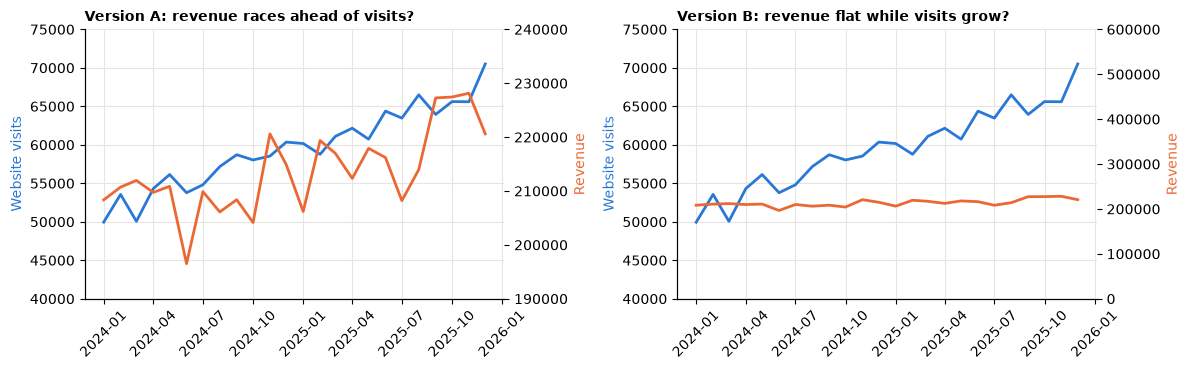

In [18]:
months = pd.date_range("2024-01-01", periods=24, freq="MS")
visits = pd.Series(50_000 + np.arange(24) * 800 + rng.normal(0, 1_500, 24), index=months)
revenue = pd.Series(200_000 + np.arange(24) * 1_200 + rng.normal(0, 6_000, 24), index=months)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
right_limits = [(190_000, 240_000), (0, 600_000)]
titles = ["Version A: revenue races ahead of visits?", "Version B: revenue flat while visits grow?"]
for ax, (low, high), title in zip(axes, right_limits, titles):
    ax.plot(visits, color=BLUE, linewidth=2)
    ax.set_ylim(40_000, 75_000)
    ax.set_ylabel("Website visits", color=BLUE)
    right = ax.twinx()
    right.plot(revenue, color=ORANGE, linewidth=2)
    right.set_ylim(low, high)
    right.set_ylabel("Revenue", color=ORANGE)
    right.grid(False)
    ax.set_title(title, fontsize=10)
    ax.tick_params(axis="x", labelrotation=45)
fig.tight_layout()
plt.show()

Same data, opposite impressions, and the crossing point of the two lines means nothing at all. A fairer comparison of **growth** puts both on one scale by **indexing**: divide each series by its first value and multiply by 100.

/var/folders/qr/z61dfxk90914kcsdy7jskgqr0000gn/T/ipykernel_52694/1324167377.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  ax.set_xlim(right=indexed.index[-1] + pd.Timedelta(days=150))


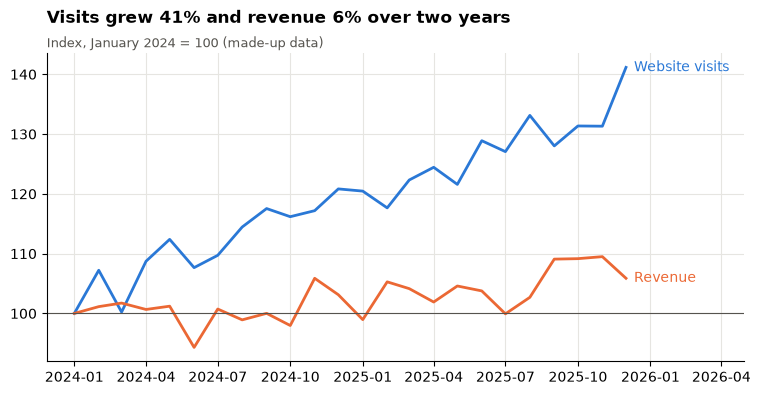

In [19]:
indexed = pd.DataFrame({
    "Website visits": visits / visits.iloc[0] * 100,
    "Revenue": revenue / revenue.iloc[0] * 100,
})

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(indexed.index, indexed["Website visits"], color=BLUE, linewidth=2)
ax.plot(indexed.index, indexed["Revenue"], color=ORANGE, linewidth=2)
ax.axhline(100, color=INK, linewidth=0.8)
for name, colour in [("Website visits", BLUE), ("Revenue", ORANGE)]:
    ax.text(indexed.index[-1], indexed[name].iloc[-1], f"  {name}", color=colour, va="center")
ax.set_xlim(right=indexed.index[-1] + pd.Timedelta(days=150))
growth_v = indexed["Website visits"].iloc[-1] - 100
growth_r = indexed["Revenue"].iloc[-1] - 100
ax.set_title(f"Visits grew {growth_v:.0f}% and revenue {growth_r:.0f}% over two years", pad=22)
ax.text(0, 1.02, "Index, January 2024 = 100 (made-up data)", transform=ax.transAxes, fontsize=9, color=INK)
plt.show()

> **Check your understanding 5**
>
> For each, is a non-zero axis acceptable? Explain in one sentence.
>
> 1. A bar chart of profit ratio by segment.
> 2. A line chart of daily share price over one month.
> 3. A dot plot of average delivery days by carrier, with the axis labelled.

---

## Part 8: Message titles and annotation

A **descriptive title** ("Monthly sales") tells the reader what is on the chart. A **message title** tells them what to **see** ("Sales peak in the last months of every year"). Managers read titles first and sometimes only titles.

Two rules:

1. The message must be **true for the chart as drawn**: same period, same filters. If the data change, re-check the title.
2. Keep the **scope** (period, population, units) in a subtitle or note, so the message stays short.

Before:

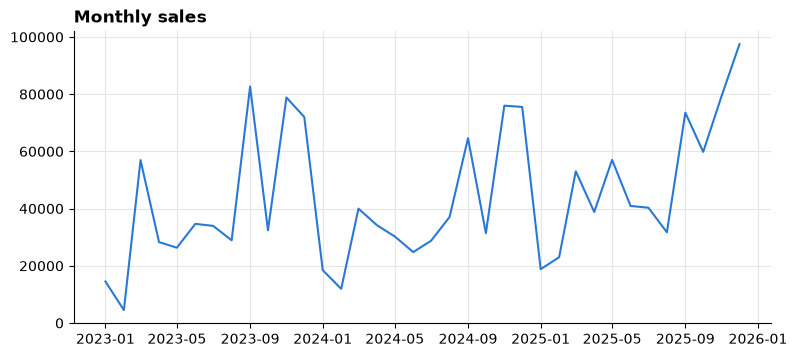

In [20]:
monthly = df.groupby("order_month")["sales"].sum()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(monthly.index, monthly)
ax.set_title("Monthly sales")
plt.show()

After: the line in grey, each year's highest month marked in orange and labelled, and a message title. The code checks the claim before it writes it: the title only says "every year" if each year's peak really falls in the last four months.

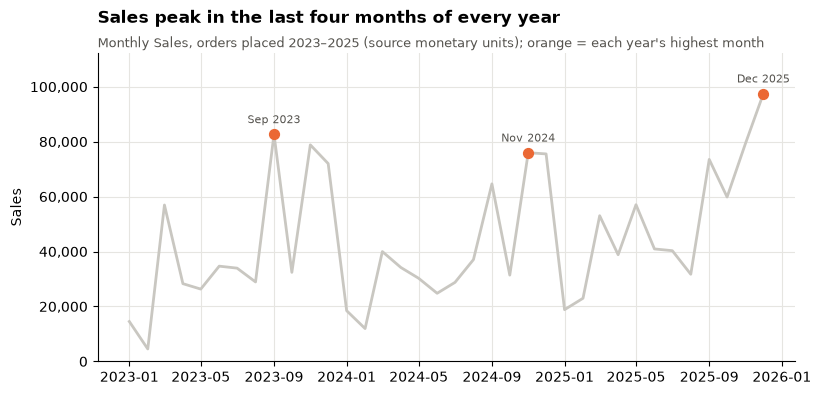

In [21]:
peaks = monthly.groupby(monthly.index.year).idxmax()

if all(month.month >= 9 for month in peaks):
    message = "Sales peak in the last four months of every year"
else:
    message = "The busiest month changes from year to year"

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly, color=GREY, linewidth=2)
ax.scatter(peaks, monthly[peaks], color=ORANGE, s=50, zorder=3)
for month in peaks:
    ax.annotate(month.strftime("%b %Y"), (month, monthly[month]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8, color=INK)
ax.set_ylim(0, monthly.max() * 1.15)
ax.set_title(message, pad=22)
ax.text(0, 1.02, "Monthly Sales, orders placed 2023–2025 (source monetary units); orange = each year's highest month",
        transform=ax.transAxes, fontsize=9, color=INK)
ax.set_ylabel("Sales")
commas(ax)
plt.show()

**Annotation** is text on the chart that explains one thing at the place it happens: a peak, a policy change, a missing month. Use it sparingly: one to three notes per chart.

> **Check your understanding 6**
>
> Rewrite each descriptive title as a message title. Invent a plausible finding; the point is the form.
>
> 1. "Returns by region, 2025"
> 2. "Average delivery days by carrier"

---

## Part 9: Small multiples

When one chart has too many series, draw **many small charts with the same axes**, one per group. Tufte called these **small multiples**. The shared axes make every panel comparable; the repetition means the reader learns to read the first panel and then reads the rest instantly.

Here each panel shows one region's quarterly Sales in blue, with the other regions in grey for context. Panels are ordered by total Sales, largest first.

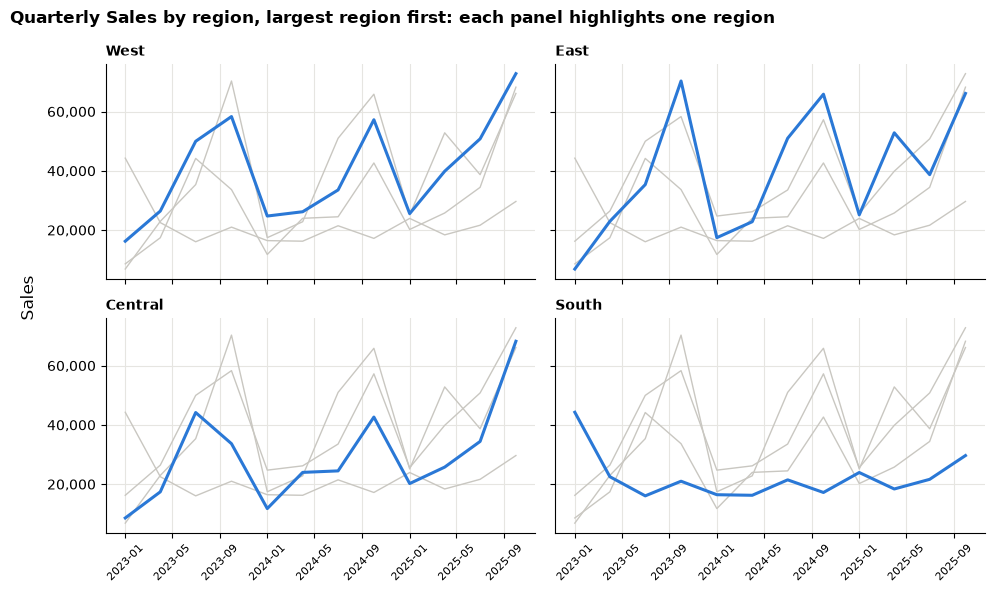

In [22]:
by_region = df.groupby([quarter, "region"])["sales"].sum().unstack()
by_region = by_region[by_region.sum().sort_values(ascending=False).index]  # biggest region first

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, region in zip(axes.flat, by_region.columns):
    for other in by_region.columns:
        if other != region:
            ax.plot(by_region.index, by_region[other], color=GREY, linewidth=1)
    ax.plot(by_region.index, by_region[region], color=BLUE, linewidth=2.2)
    ax.set_title(region, fontsize=10)
    ax.tick_params(axis="x", labelsize=8, labelrotation=45)
    commas(ax)
fig.suptitle("Quarterly Sales by region, largest region first: each panel highlights one region", x=0.01, ha="left",
             fontweight="bold")
fig.supylabel("Sales")
fig.tight_layout()
plt.show()

> **Small multiples checklist**
>
> 1. Same axes in every panel (`sharex=True, sharey=True`), unless you say clearly that they differ.
> 2. Panels in a meaningful order (by size, by geography, by time), not alphabetical by default.
> 3. One highlight colour, the same in every panel.

---

## Summary

| Idea | One-line takeaway |
|---|---|
| Task first | Compare → bars; distribution → histogram; relationship → scatter; time → line |
| Encodings | Position and length are read best; angle, area and colour worse |
| Pre-attentive | One strong colour against grey; never several highlights |
| Data-ink | Remove what does not carry data; keep units, scope and meaningful reference lines |
| Gestalt | Put next to each other what the reader must compare |
| Colour | Categorical, sequential or diverging by the data; colour-blind safe; not colour alone |
| Honest axes | Bars from zero; lines may zoom with labels; avoid dual axes, index instead |
| Titles | Message title, scope in a subtitle, one to three annotations |
| Small multiples | Same axes, many panels, one highlight |

---

## Quiz

Answer these at the start of the next lecture. Write short answers.

1. Name the five chart tasks from Part 1 and a good first chart for each.
2. Why is a pie chart with ten slices hard to read? Use the word "encoding" in your answer.
3. What is a pre-attentive attribute? Give two examples and one way to misuse them.
4. Name three kinds of non-data ink you would remove from a default chart, and one element you must keep.
5. Which Gestalt principle explains why grouping bars by region makes segment comparisons easy?
6. You show profit change by department, where some departments improved and some got worse. Which palette type do you use, and where must its neutral colour sit?
7. Why must a bar chart start at zero when a line chart need not?
8. A colleague's dual-axis chart shows revenue and visits "crossing" in March. What do you tell them, and what would you draw instead?

---

## In the Lab

In the [Session 6 lab](06_visualisation_principles_lab.md) you will:

1. Build a small **style helper** you can reuse for every chart in the course.
2. Redesign three bad charts on the Superstore data: a crowded pie, a truncated bar axis and a rainbow line "spaghetti".
3. Draw one-, two- and many-variable views: a histogram, a discount-versus-profit scatter and small multiples by region.
4. Challenge: build one decision chart with a message title and annotation, and critique a colleague's dual-axis chart.

**Evidence to bring back:** before/after chart pairs, each with a short written critique.